# **Section 7: Decision Trees**

In this notebook, I will train and evaluate decision trees. I will start with a basic tree with default parameters, and will then tune the tree complexity (max_depth and min_samples_split) using a cross-validated grid search.

#### **Contents**
1. **Import data**
2. **Basic decision tree**
    - 2.1 Training and fitting the model
    - 2.2 Evaluating the model
    - 2.3 Classification report and confusion matrix
3. **Hyperparameter optimization**
   - 3.1 Grid search
   - 3.2 Visualizing training / validation curves
4. **Best model evaluation**
   - 4.1. Test set accuracy
   - 4.2 Classification report and confusion matrix
   - 4.3 ROC curve and AUC score
5. **Biomarker identification**
   - 5.1 Load cluster names
   - 5.2 Extract feature importance
   - 5.3 Export biomarkers
6. **Saving model results**


## **1. Importing the data**
Let's import the training and test sets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

sns.set_palette("pastel")

In [2]:
# Load features and labels
sv_train = pd.read_csv("Data/sv_train_selected.csv", index_col=0)
sv_test = pd.read_csv("Data/sv_test_selected.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train_selected.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test_selected.csv", index_col=0)

X_train = sv_train.values
y_train = profiles_train.values.ravel()

X_test = sv_test.values
y_test = profiles_test.values.ravel()

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Categories: {np.unique(y_train)}")

Training set shape: (177, 199)
Test set shape: (50, 199)
Categories: [0 1]


## **2. Basic decision tree**

### **2.1 Training and fitting the model**
Let's start with a basic decision tree using default parameters.

In [3]:
# Create Decision Tree
dt = DecisionTreeClassifier(random_state=10)

# Train the model
dt.fit(X_train, y_train)

print("Decision Tree model trained")
print(f"Tree depth: {dt.get_depth()}")
print(f"Number of leaves: {dt.get_n_leaves()}")

Decision Tree model trained
Tree depth: 15
Number of leaves: 35


### **2.2 Evaluating the model**

In [4]:
# Evaluate on training and test sets
accuracy_train = dt.score(X_train, y_train)
accuracy_test = dt.score(X_test, y_test)

print(f"Accuracy training set: {accuracy_train:.4f}")
print(f"Accuracy test set: {accuracy_test:.4f}")

Accuracy training set: 1.0000
Accuracy test set: 0.5400


### **2.3 Classification report and confusion matrix**

In [5]:
# Get predictions
y_test_pred = dt.predict(X_test)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.53      0.58        30
           1       0.44      0.55      0.49        20

    accuracy                           0.54        50
   macro avg       0.54      0.54      0.54        50
weighted avg       0.56      0.54      0.54        50



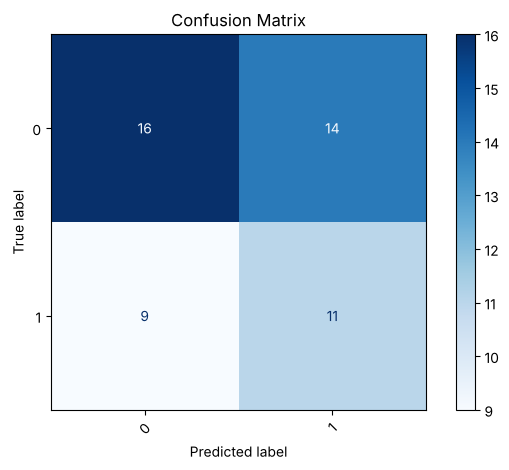

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=dt.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dt.classes_)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## **3. Hyperparameter Tuning: optimizing tree complexity**

Now let's use cross-validated grid search to tune the tree complexity parameters (max_depth and min_samples_split).

### **3.1 Grid search**

In [7]:
# Define parameter grid
param_grid = {
    'max_depth': [1, 2, 3, 4, 5, 7, 10],
    'min_samples_split': [2, 5, 10, 20]
}

# Create grid search
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    return_train_score=True,
    n_jobs=-1
)

# Perform grid search
grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")


Best parameters: {'max_depth': 4, 'min_samples_split': 2}
Best cross-validation score: 0.6775


In [8]:
cv_results = pd.DataFrame(grid_search.cv_results_)

print(cv_results.loc[:,['mean_test_score', 'std_test_score',
    'mean_train_score', 'std_train_score',
    'param_max_depth', 'param_min_samples_split'
]].head())

   mean_test_score  std_test_score  mean_train_score  std_train_score  \
0         0.587143        0.055683          0.696354         0.011928   
1         0.587143        0.055683          0.696354         0.011928   
2         0.587143        0.055683          0.696354         0.011928   
3         0.587143        0.055683          0.696354         0.011928   
4         0.598254        0.082093          0.769803         0.019442   

   param_max_depth  param_min_samples_split  
0                1                        2  
1                1                        5  
2                1                       10  
3                1                       20  
4                2                        2  


### **3.2 Visualize training/validation curves**

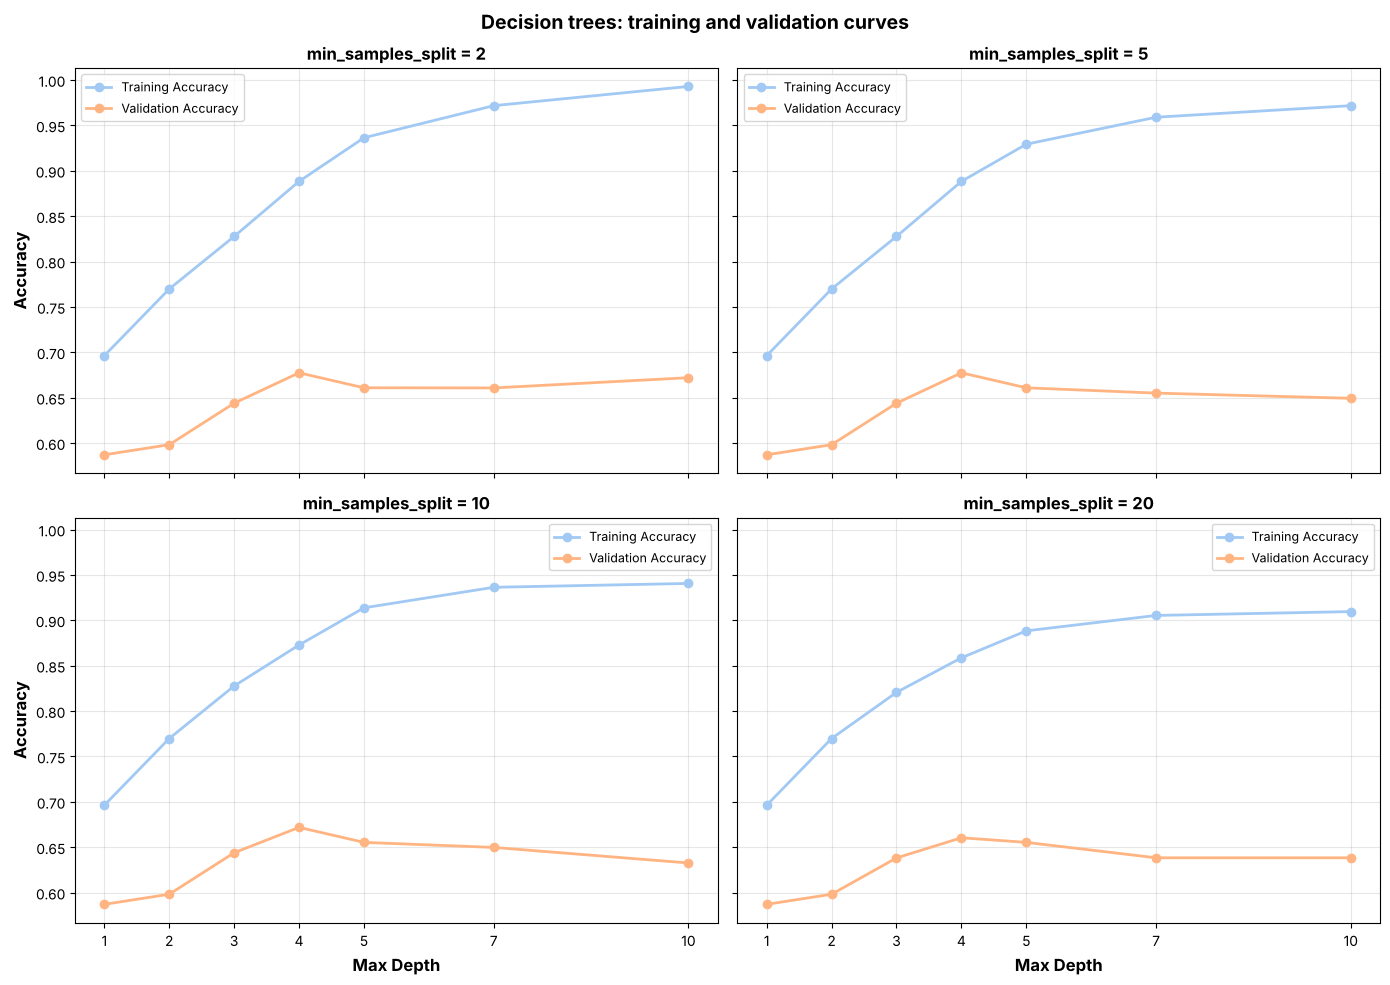

In [9]:
split_values = sorted(cv_results['param_min_samples_split'].unique())
depths = sorted(cv_results['param_max_depth'].unique())

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

for ax, split in zip(axes.flat, split_values):
    subset = (cv_results[cv_results['param_min_samples_split'] == split].sort_values('param_max_depth'))
    x = subset['param_max_depth']

    ax.plot(x, subset['mean_train_score'], label='Training Accuracy', marker='o', linewidth=2)
    ax.plot(x, subset['mean_test_score'], label='Validation Accuracy', marker='o', linewidth=2)

    ax.set_title(f'min_samples_split = {split}', fontsize=12, fontweight='bold')
    ax.set_xticks(depths)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

for ax in axes[1, :]:
    ax.set_xlabel('Max Depth', fontsize=12, fontweight='bold')
for ax in axes[:, 0]:
    ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')

fig.suptitle('Decision trees: training and validation curves',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("Figures/07_dt_training_curve.png", dpi=300)
plt.show()

## **4. Evaluate Best Model**

### **4.1 Test set accuracy**

In [10]:
# Evaluate best model on test set
best_dt = grid_search.best_estimator_
accuracy_test_best = best_dt.score(X_test, y_test)

print(f"\nBest Model Test Accuracy: {accuracy_test_best:.4f}")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.4f}")
print(f"Tree depth: {best_dt.get_depth()}")
print(f"Number of leaves: {best_dt.get_n_leaves()}")


Best Model Test Accuracy: 0.6200
Best parameters: {'max_depth': 4, 'min_samples_split': 2}
Best CV score: 0.6775
Tree depth: 4
Number of leaves: 12


### **4.2 Classification report and confusion matrix**

In [11]:
# Get predictions
y_test_pred_best = best_dt.predict(X_test)

# Classification report
print("\nClassification Report (Best DT):")
print(classification_report(y_test, y_test_pred_best))


Classification Report (Best DT):
              precision    recall  f1-score   support

           0       0.69      0.67      0.68        30
           1       0.52      0.55      0.54        20

    accuracy                           0.62        50
   macro avg       0.61      0.61      0.61        50
weighted avg       0.62      0.62      0.62        50



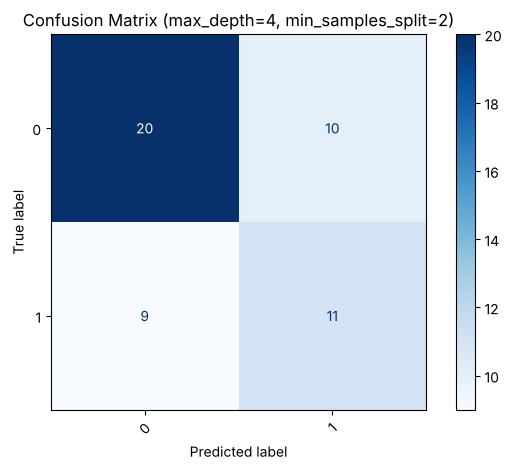

In [12]:
# Confusion matrix
cm_best = confusion_matrix(y_test, y_test_pred_best, labels=best_dt.classes_)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=best_dt.classes_)
disp_best.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion Matrix (max_depth={grid_search.best_params_['max_depth']}, min_samples_split={grid_search.best_params_['min_samples_split']})")
plt.tight_layout()
plt.savefig("Figures/07_dt_cm.png", dpi=300)
plt.show()

### **4.3 ROC Curve and AUC score**

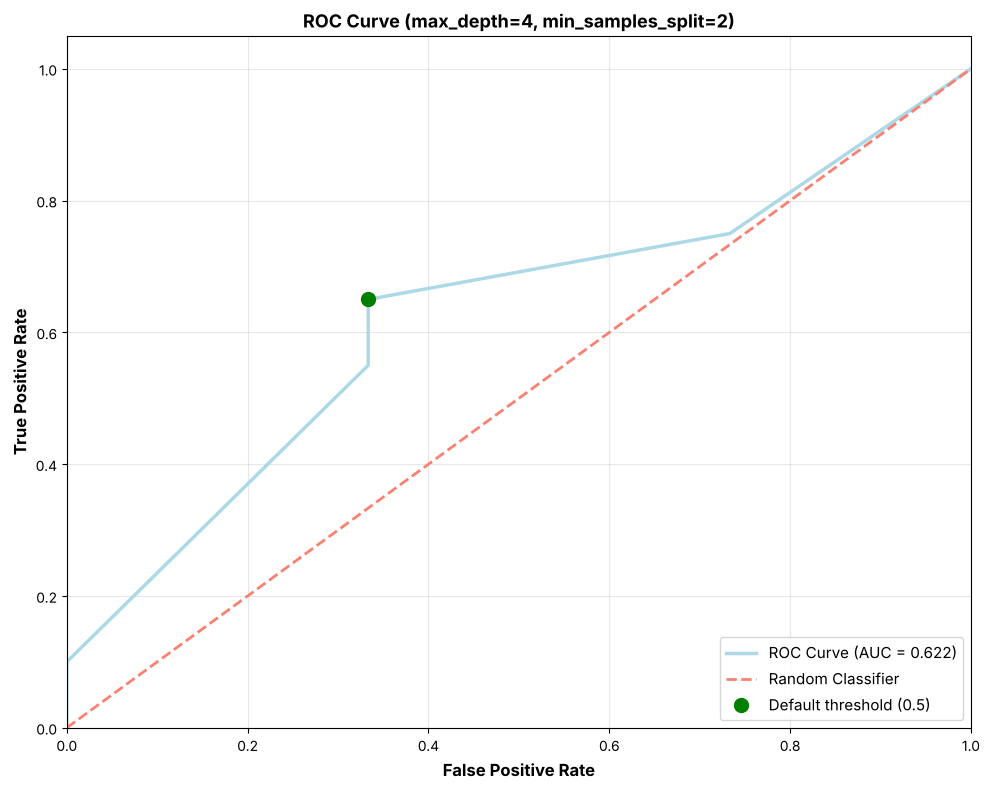


AUC Score: 0.6217
At default threshold (0.5):
True Positive Rate: 0.650 (detects 65.0% of resistants)
False Positive Rate: 0.333 (33.3% of susceptibles are misclassified)


In [13]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Get probability predictions for the positive class
y_test_proba = best_dt.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='lightblue', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='salmon', lw=2, linestyle='--', label='Random Classifier')

# Mark 0.5 threshold
default_idx = np.argmin(np.abs(thresholds - 0.5))
plt.plot(fpr[default_idx], tpr[default_idx], 'go', markersize=10, label='Default threshold (0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title(f'ROC Curve (max_depth={grid_search.best_params_["max_depth"]}, min_samples_split={grid_search.best_params_["min_samples_split"]})', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/07_dt_ROC.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAUC Score: {roc_auc:.4f}")
print(f"At default threshold (0.5):")
print(f"True Positive Rate: {tpr[default_idx]:.3f} (detects {tpr[default_idx]*100:.1f}% of resistants)")
print(f"False Positive Rate: {fpr[default_idx]:.3f} ({fpr[default_idx]*100:.1f}% of susceptibles are misclassified)")

## **5. Biomarker Identification**
Let's now have a look at which features contribute the most to the model.

We will identify which features were used by the best decision tree to classify the samples by looking at the gini importance for each feature. We can access this using *best_dt.feature_importances_*

### **5.1 Load feature names**
We now don't have access directly to the original features, as they were grouped into clusters in the third notebook. We do however have the cluster numbers (the column names of the feature matrix), and a list of the SVs in each cluster (with their SV type and length) in the file Data/clusters.csv.

In [14]:
cluster_names = sv_train.columns.astype(int).values
features_to_cluster = pd.read_csv("Data/clusters.csv")
features_to_cluster.head()

,cluster,feature,cluster_size,svtype,svlen
0,0,sv__NZ_CP009157.1_4016031_4016119_INV,1,INV,88
1,1,sv__NZ_CP009157.1_1200812_1200910_DEL,1,DEL,98
2,2,sv__NZ_CP009157.1_729822_729873_INV,1,INV,51
3,3,sv__NZ_CP009156.1_3103819_3103911_INV,1,INV,92
4,4,sv__NZ_CP009156.1_2702723_2702784_INV,1,INV,61


### **5.2 Feature Importance**

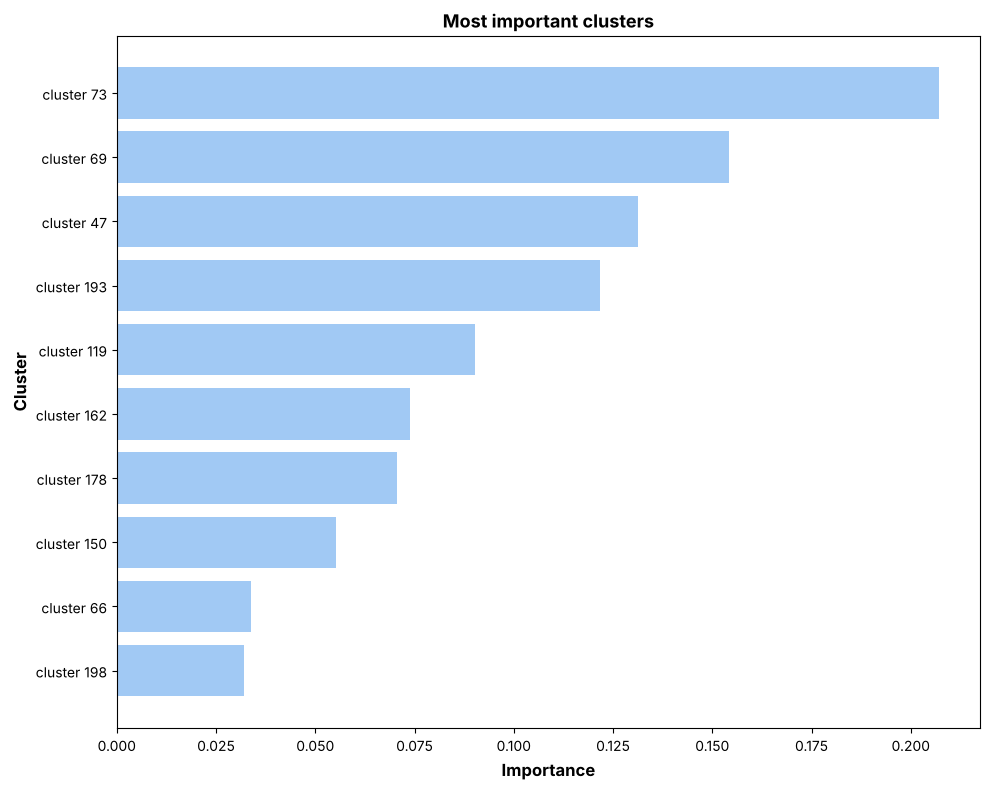

In [15]:
# Get feature importances
feature_importance = best_dt.feature_importances_
feature_importance_df = pd.DataFrame({
    'cluster': cluster_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

# Plot top 10 features (clusters)
n_top = min(10, len(feature_importance_df))
plt.figure(figsize=(10, 8))
plt.barh(range(n_top), feature_importance_df['importance'].head(n_top))
plt.yticks(range(n_top), [f'cluster {c}' for c in feature_importance_df['cluster'].head(n_top)])
plt.xlabel('Importance', fontsize=12, fontweight='bold')
plt.ylabel('Cluster', fontsize=12, fontweight='bold')
plt.title('Most important clusters', fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("Figures/07_dt_feature_importance.png", dpi=300)
plt.show()

A decision tree only uses a few features. Let's keep the clusters the tree actually uses (importance > 0) and see which SVs they contain.

In [16]:
used_clusters = feature_importance_df[feature_importance_df['importance'] > 0]
print(f"The tree uses {len(used_clusters)} clusters")
print(features_to_cluster[features_to_cluster.cluster.isin(used_clusters['cluster'])])

The tree uses 11 clusters
     cluster                                feature  cluster_size svtype  \
47        47  sv__NZ_CP009157.1_1701836_1701889_INV             1    INV   
66        66  sv__NZ_CP009157.1_2321254_3013198_INV             1    INV   
69        69  sv__NZ_CP009156.1_3007890_3007988_INV             1    INV   
73        73      sv__NZ_CP009156.1_81858_81956_DEL             1    DEL   
120      119  sv__NZ_CP009156.1_2957713_2957791_INV             1    INV   
140      139    sv__NZ_CP009156.1_627260_627319_INV             1    INV   
151      150  sv__NZ_CP009156.1_1794244_1794315_DEL             1    DEL   
163      162  sv__NZ_CP009156.1_2889794_2889895_DEL             1    DEL   
179      178  sv__NZ_CP009157.1_2646716_2646770_DEL             1    DEL   
194      193    sv__NZ_CP009156.1_354822_355389_DEL             1    DEL   
199      198  sv__NZ_CP009156.1_1014118_1014171_INV             1    INV   

      svlen  
47       53  
66   691944  
69       98  
73   

It will be interesting to compare this list to the features identified with the other models, and see if some features are common to several models. Let's save these features in a csv file for further analysis.

### **5.3 Save Biomarker results**

In [17]:
# Save biomarker results: the SVs of the top 100 clusters, with the model's score for their cluster
top_clusters = used_clusters.head(100)[['cluster', 'importance']]
biomarkers = features_to_cluster.merge(top_clusters, on='cluster')
biomarkers.to_csv("Results/biomarkers_dt.csv", index=False)
print(f"{len(biomarkers)} SVs in the top {len(top_clusters)} clusters saved to Results/biomarkers_dt.csv")

11 SVs in the top 11 clusters saved to Results/biomarkers_dt.csv


## **6. Save model results**

In [18]:
import csv
import os

# Store results
results = {
    'model': 'Decision Tree',
    'hyperparameters': f"max_depth={grid_search.best_params_['max_depth']}, min_samples_split={grid_search.best_params_['min_samples_split']}",
    'test_accuracy': float(accuracy_test_best),
    'cv_score': float(grid_search.best_score_)
}

csv_file = "Results/model_results.csv"

# Append results to the csv file
if not os.path.exists(csv_file):
    with open(csv_file, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writeheader()
        writer.writerow(results)
else:
    with open(csv_file, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writerow(results)

print(f"\nResults saved:")
print(f"Model: {results['model']}")
print(f"Hyperparameters: {results['hyperparameters']}")
print(f"Test Accuracy: {results['test_accuracy']:.4f}")
print(f"CV Score: {results['cv_score']:.4f}")


Results saved:
Model: Decision Tree
Hyperparameters: max_depth=4, min_samples_split=2
Test Accuracy: 0.6200
CV Score: 0.6775
